# Bank Loan Data Cleaning with Pandas

This practice notebook checks nulls and duplicates, cleans a numeric-like text column (`CCAvg`), and plots a distribution.

## 1. Load and inspect

In [6]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

source = Path("data/bank_loan_example.csv")
loan_cleaning = pd.read_csv(source)
print("Rows / columns:", loan_cleaning.shape)
display(loan_cleaning.head())
loan_cleaning.info()

Rows / columns: (5000, 14)


,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91108,4,1/60,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1/50,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1/00,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2/70,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1/00,2,0,0,0,0,0,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   ID                  5000 non-null   int64 
 1   Age                 5000 non-null   int64 
 2   Experience          5000 non-null   int64 
 3   Income              5000 non-null   int64 
 4   ZIP Code            5000 non-null   int64 
 5   Family              5000 non-null   int64 
 6   CCAvg               5000 non-null   object
 7   Education           5000 non-null   int64 
 8   Mortgage            5000 non-null   int64 
 9   Personal Loan       5000 non-null   int64 
 10  Securities Account  5000 non-null   int64 
 11  CD Account          5000 non-null   int64 
 12  Online              5000 non-null   int64 
 13  CreditCard          5000 non-null   int64 
dtypes: int64(13), object(1)
memory usage: 547.0+ KB


## 2. Check missing and duplicate records

In [7]:
print("Missing values by column:")
print(loan_cleaning.isna().sum())
print("Duplicate rows before:", loan_cleaning.duplicated().sum())
loan_cleaning = loan_cleaning.drop_duplicates().copy()
print("Duplicate rows after:", loan_cleaning.duplicated().sum())

Missing values by column:
ID                    0
Age                   0
Experience            0
Income                0
ZIP Code              0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal Loan         0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
dtype: int64
Duplicate rows before: 0
Duplicate rows after: 0


## 3. Investigate and convert `CCAvg`

In this learning exercise, the data format **assumes `/` means a decimal point**, such that `1/60` represents `1.60`. This is a dataset-specific cleaning rule, **not** a general interpretation of slash-separated numbers.

In [8]:
print("Type before:", loan_cleaning["CCAvg"].dtype)
print("Example values:", loan_cleaning["CCAvg"].astype(str).unique()[:10])
loan_cleaning["CCAvg"] = (
    loan_cleaning["CCAvg"].astype(str).str.replace("/", ".", regex=False)
)
loan_cleaning["CCAvg"] = pd.to_numeric(loan_cleaning["CCAvg"], errors="raise")
print("Type after:", loan_cleaning["CCAvg"].dtype)
print(loan_cleaning["CCAvg"].describe())

Type before: object
Example values: ['1/60' '1/50' '1/00' '2/70' '0/40' '0/30' '0/60' '8/90' '2/40' '0/10']
Type after: float64
count    5000.000000
mean        1.937938
std         1.747659
min         0.000000
25%         0.700000
50%         1.500000
75%         2.500000
max        10.000000
Name: CCAvg, dtype: float64


## 4. Visualize and export cleaned data

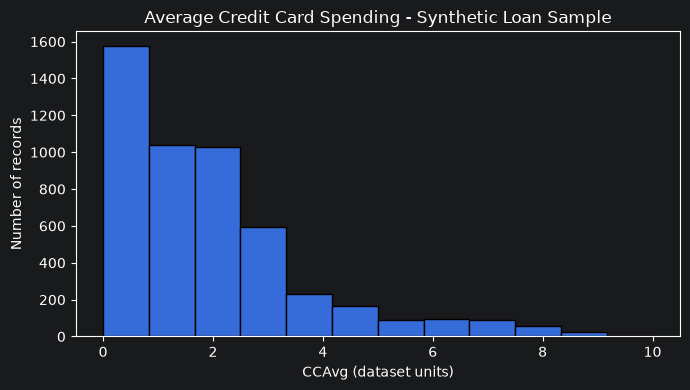

Saved: output\bank_loan_cleaned.csv | rows: 5000


In [9]:
plt.figure(figsize=(7, 4))
plt.hist(loan_cleaning["CCAvg"], bins=12, edgecolor="black")
plt.title("Average Credit Card Spending - Synthetic Loan Sample")
plt.xlabel("CCAvg (dataset units)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

output_dir = Path("output")
output_dir.mkdir(exist_ok=True)
outfile = output_dir / "bank_loan_cleaned.csv"
loan_cleaning.to_csv(outfile, index=False)
print("Saved:", outfile, "| rows:", len(loan_cleaning))

## Result

The sample contains deliberately duplicated rows and mixed `CCAvg` string formats. The notebook removes the duplicates and converts `CCAvg` to numeric for analysis. It does **not** establish findings about a real loan portfolio.